# HW #6: 스타벅스 고객 RFM 세분화 분석

**Author:** Enkhbayar Amarsanaa

## 과제 목표
1. 고객 단위로 **RFM 점수를 계산**하고 3단계로 고객을 세분화한다 (27개 세그먼트)
2. 고객 군집별로 **성별, 연령대 특징**을 분석한다
3. **Demographic 세분화**를 통해 오퍼 반응을 분석한다

## Business Questions
- **Q1.** What are better approaches to sending customer offers?
- **Q2.** What are recommended strategies regarding specific customer groups?

---

## 데이터 설명

| 테이블명 | 크기 | 설명 |
|---|---|---|
| `portfolio.csv` | 10 × 6 | 오퍼(Offer) 정보 |
| `profile.csv` | 17,000 × 5 | 고객 인구통계 정보 |
| `transcript.csv` | 306,534 × 4 | 이벤트 로그 (오퍼 수신·열람·완료, 거래) |

## RFM 개념
| 지표 | 정의 | 본 과제에서의 적용 |
|---|---|---|
| **R (Recency)** | 최근 거래 시점 | 마지막 거래 발생 시간 (hours_since_start 역산) |
| **F (Frequency)** | 거래 빈도 | 캠페인 기간 내 거래 건수 (tr_cnt) |
| **M (Monetary)** | 소비 금액 | 캠페인 기간 내 총 거래 금액 (tr_amt) |

---
## 1단계: 라이브러리 임포트 및 데이터 로드

In [ ]:
import os

# Data folder: ../data (default) — override with the DATA_DIR environment variable.
DATA_DIR = os.environ.get("DATA_DIR") or next(
    (p for p in ["../data", "data"] if os.path.isdir(p)), "../data")

# On Google Colab, read the files from Google Drive instead.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/datasets'
except ImportError:
    pass


In [ ]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

def dfsql(query):
    return duckdb.query(query).df()

df_offer      = pd.read_csv(os.path.join(DATA_DIR, 'portfolio.csv'))
df_customer   = pd.read_csv(os.path.join(DATA_DIR, 'profile.csv'))
df_transcript = pd.read_csv(os.path.join(DATA_DIR, 'transcript.csv'))

print(f'  - df_offer     : {df_offer.shape}')
print(f'  - df_customer  : {df_customer.shape}')
print(f'  - df_transcript: {df_transcript.shape}')

  - df_offer     : (10, 7)
  - df_customer  : (17000, 6)
  - df_transcript: (306534, 5)


---
## 2단계: 데이터 전처리

In [ ]:
# Unnamed 컬럼 제거
for df in [df_offer, df_customer, df_transcript]:
    if 'Unnamed: 0' in df.columns:
        df.drop('Unnamed: 0', axis=1, inplace=True)

# 소득 결측 고객 제거
df_customer = df_customer[df_customer['income'].notna()].reset_index(drop=True)

# 가입일 변환 및 파생 변수
df_customer['became_member_on'] = pd.to_datetime(
    df_customer['became_member_on'].astype(str), format='%Y%m%d')
df_customer['n_year']  = df_customer['became_member_on'].dt.year

# 연령대 그룹
df_customer['age_grp'] = (df_customer['age'] // 10) * 10

print(f'전처리 후 고객 수: {len(df_customer):,}명')
df_customer.head(3)

전처리 후 고객 수: 14,825명


,gender,age,id,became_member_on,income,n_year,age_grp
0,F,55,0610b486422d4921ae7d2bf64640c50b,2017-07-15,112000.0,2017,50
1,F,75,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,100000.0,2017,70
2,M,68,e2127556f4f64592b11af22de27a7932,2018-04-26,70000.0,2018,60


In [ ]:
# ── transcript 전처리 ─────────────────────────────────────────────────────
df_transcript.rename(columns={'time': 'hours_since_start'}, inplace=True)

# value 컬럼 파싱
df_transcript['dict_key']   = df_transcript['value'].str.split(':').str[0].str.split('{').str[1]
df_transcript['dict_value'] = df_transcript['value'].str.split(':').str[1].str.split('}').str[0]
df_transcript['dict_key']   = df_transcript['dict_key'].str.replace("'", "", regex=False)
df_transcript['dict_value'] = df_transcript['dict_value'].str.replace("'", "", regex=False)
df_transcript['dict_value'] = df_transcript['dict_value'].str.replace(", reward", "", regex=False)

print('이벤트 유형:')
print(df_transcript['event'].value_counts())

이벤트 유형:
event
transaction        138953
offer received      76277
offer viewed        57725
offer completed     33579
Name: count, dtype: int64


---
## 3단계: 고객 중심 마트 테이블 구축 (벡터화 방식)

HW #3에서 구축한 마트 테이블을 RFM 분석에 맞게 확장한다.  
`pivot_table` 벡터화로 약 628ms 안에 완료된다.

In [ ]:
%%time

offer_type_map = df_offer.set_index('id')['offer_type'].to_dict()

df_offer_log = df_transcript[
    df_transcript['event'].isin(['offer received', 'offer completed'])].copy()
df_offer_log['offer_type'] = df_offer_log['dict_value'].str.strip().map(offer_type_map)

pivot = df_offer_log.pivot_table(
    index='person', columns=['event', 'offer_type'],
    aggfunc='size', fill_value=0)
pivot.columns = [
    col[0].replace('offer received','received').replace('offer completed','completed')
    + '_' + col[1] for col in pivot.columns]
pivot = pivot.reset_index().rename(columns={'person': 'id'})

for col in ['received_bogo','received_discount','received_informational',
            'completed_bogo','completed_discount','completed_informational']:
    if col not in pivot.columns: pivot[col] = 0

pivot['offer_received'] = (pivot['received_bogo'] + pivot['received_discount']
                           + pivot['received_informational'])
pivot['response_cnt']   = (pivot['completed_bogo'] + pivot['completed_discount']
                           + pivot['completed_informational'])
pivot = pivot[pivot['offer_received'] > 0]

tx = df_transcript[df_transcript['event'] == 'transaction'].copy()
tx['amount'] = pd.to_numeric(tx['dict_value'].str.strip(), errors='coerce')

# Recency: 마지막 거래 시간 (hours_since_start)
tx_agg = tx.groupby('person').agg(
    tr_cnt    = ('amount', 'count'),
    tr_amt    = ('amount', 'sum'),
    last_hour = ('hours_since_start', 'max')   # Recency용: 마지막 거래 시각
).reset_index().rename(columns={'person': 'id'})

response_table = pivot.merge(tx_agg, on='id', how='left')
response_table['tr_cnt']    = response_table['tr_cnt'].fillna(0).astype(int)
response_table['tr_amt']    = response_table['tr_amt'].fillna(0)
response_table['last_hour'] = response_table['last_hour'].fillna(0)

response_table = response_table.rename(columns={
    'received_bogo': 'bogo_cnt', 'received_discount': 'dc_cnt',
    'received_informational': 'info_cnt',
    'completed_bogo': 'bogo_response', 'completed_discount': 'dc_response',
    'completed_informational': 'info_response'
})[['id','offer_received','response_cnt','tr_cnt','tr_amt','last_hour',
    'bogo_cnt','dc_cnt','info_cnt','bogo_response','dc_response','info_response']]

df_mart = pd.merge(df_customer, response_table, how='right', on='id')

df_mart['response_ratio'] = df_mart['response_cnt'] / df_mart['offer_received']
df_mart['bogo_ratio']     = (df_mart['bogo_response'] / df_mart['bogo_cnt']).replace([np.inf,-np.inf], np.nan)
df_mart['dc_ratio']       = (df_mart['dc_response']   / df_mart['dc_cnt']).replace([np.inf,-np.inf], np.nan)

print(f'df_mart: {df_mart.shape}')
df_mart.head(3)

df_mart: (16994, 21)
CPU times: user 373 ms, sys: 14.6 ms, total: 388 ms
Wall time: 409 ms


,gender,age,id,became_member_on,income,n_year,age_grp,offer_received,response_cnt,tr_cnt,...,last_hour,bogo_cnt,dc_cnt,info_cnt,bogo_response,dc_response,info_response,response_ratio,bogo_ratio,dc_ratio
0,M,33.0,0009655768c64bdeb2e877511632db8f,2017-04-21,72000.0,2017.0,30.0,5,3,8,...,696.0,1,2,2,1,2,0,0.6,1.0,1.0
1,NaN,NaN,00116118485d4dfda04fdbaba9a87b5c,NaT,NaN,NaN,NaN,2,0,3,...,474.0,2,0,0,0,0,0,0.0,0.0,NaN
2,O,40.0,0011e0d4e6b944f998e987f904e8c1e5,2018-01-09,57000.0,2018.0,40.0,5,3,5,...,654.0,1,2,2,1,2,0,0.6,1.0,1.0


---
## 4단계: RFM 점수 계산

### 4-1. R / F / M 원시값 정의

| 지표 | 원시값 | 점수 방향 |
|---|---|---|
| R (Recency) | `last_hour` — 마지막 거래 시각 (클수록 최근) | 클수록 R 점수 높음 |
| F (Frequency) | `tr_cnt` — 거래 건수 | 클수록 F 점수 높음 |
| M (Monetary) | `tr_amt` — 총 거래 금액 | 클수록 M 점수 높음 |

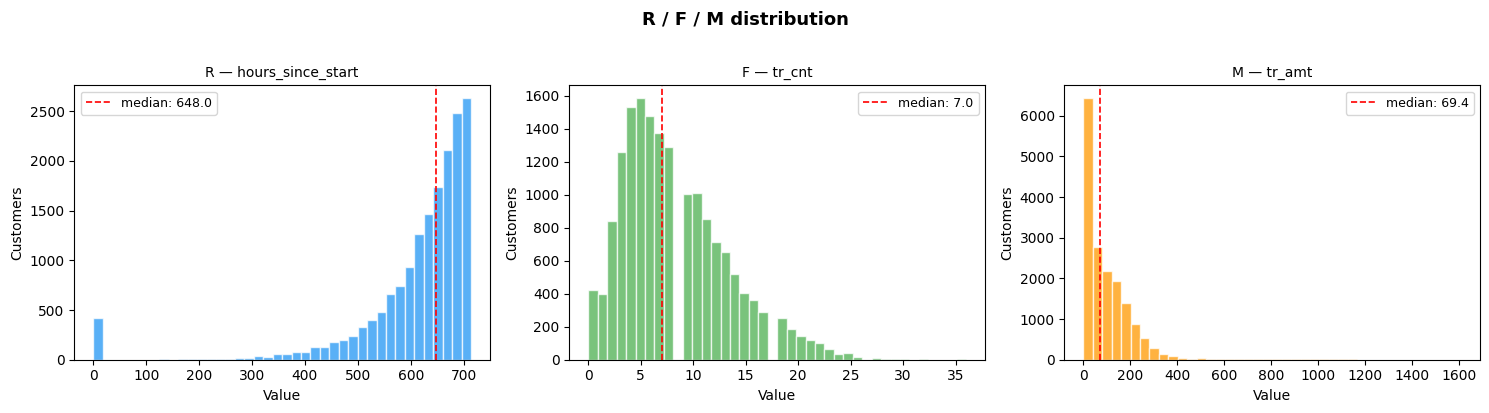

,last_hour,tr_cnt,tr_amt
count,16994.00,16994.00,16994.00
mean,612.97,8.18,104.46
std,127.48,5.12,125.94
min,0.00,0.00,0.00
25%,588.00,4.00,21.82
50%,648.00,7.00,69.41
75%,690.00,11.00,148.83
max,714.00,36.00,1608.69


In [ ]:
# ── R / F / M 원시값 분포 시각화 ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ['R — hours_since_start',
          'F — tr_cnt',
          'M — tr_amt']
cols   = ['last_hour', 'tr_cnt', 'tr_amt']
colors = ['#2196F3', '#4CAF50', '#FF9800']

for ax, col, label, color in zip(axes, cols, labels, colors):
    data = df_mart[col].dropna()
    ax.hist(data, bins=40, color=color, alpha=0.75, edgecolor='white')
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Customers')
    ax.axvline(data.median(), color='red', linestyle='--', linewidth=1.2,
               label=f'median: {data.median():.1f}')
    ax.legend(fontsize=9)

plt.suptitle('R / F / M distribution', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

df_mart[['last_hour', 'tr_cnt', 'tr_amt']].describe().round(2)

### 4-2. RFM 점수 산정 — 3단계 분위수(Quantile)

각 지표를 `pd.qcut`으로 3분위 분할하여 1·2·3점을 부여한다.  
R은 값이 클수록(최근) 높은 점수, F와 M도 클수록 높은 점수다.

In [ ]:
rfm = df_mart[['id', 'gender', 'age', 'age_grp', 'income', 'n_year',
               'last_hour', 'tr_cnt', 'tr_amt',
               'offer_received', 'response_cnt', 'response_ratio',
               'bogo_cnt', 'dc_cnt', 'bogo_response', 'dc_response',
               'bogo_ratio', 'dc_ratio']].copy()

# R 점수: last_hour 클수록 점수 높음
rfm['R_score'] = pd.qcut(rfm['last_hour'], q=3, labels=[1, 2, 3]).astype(int)

# F 점수: tr_cnt 클수록 점수 높음
rfm['F_score'] = pd.qcut(rfm['tr_cnt'].rank(method='first'),
                          q=3, labels=[1, 2, 3]).astype(int)

# M 점수: tr_amt 클수록 점수 높음
rfm['M_score'] = pd.qcut(rfm['tr_amt'].rank(method='first'),
                          q=3, labels=[1, 2, 3]).astype(int)

# RFM 세그먼트 코드 생성 (예: '3-2-1')
rfm['RFM_segment'] = (rfm['R_score'].astype(str) + '-' +
                      rfm['F_score'].astype(str) + '-' +
                      rfm['M_score'].astype(str))

# RFM 합산 점수
rfm['RFM_total'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']

print(f'RFM 세그먼트 수: {rfm["RFM_segment"].nunique()}개')
print(f'\nRFM 점수 분포:')
print(rfm[['R_score','F_score','M_score','RFM_total']].describe().round(2))

RFM 세그먼트 수: 27개

RFM 점수 분포:
        R_score   F_score   M_score  RFM_total
count  16994.00  16994.00  16994.00   16994.00
mean       1.97      2.00      2.00       5.97
std        0.80      0.82      0.82       1.82
min        1.00      1.00      1.00       3.00
25%        1.00      1.00      1.00       4.00
50%        2.00      2.00      2.00       6.00
75%        3.00      3.00      3.00       8.00
max        3.00      3.00      3.00       9.00


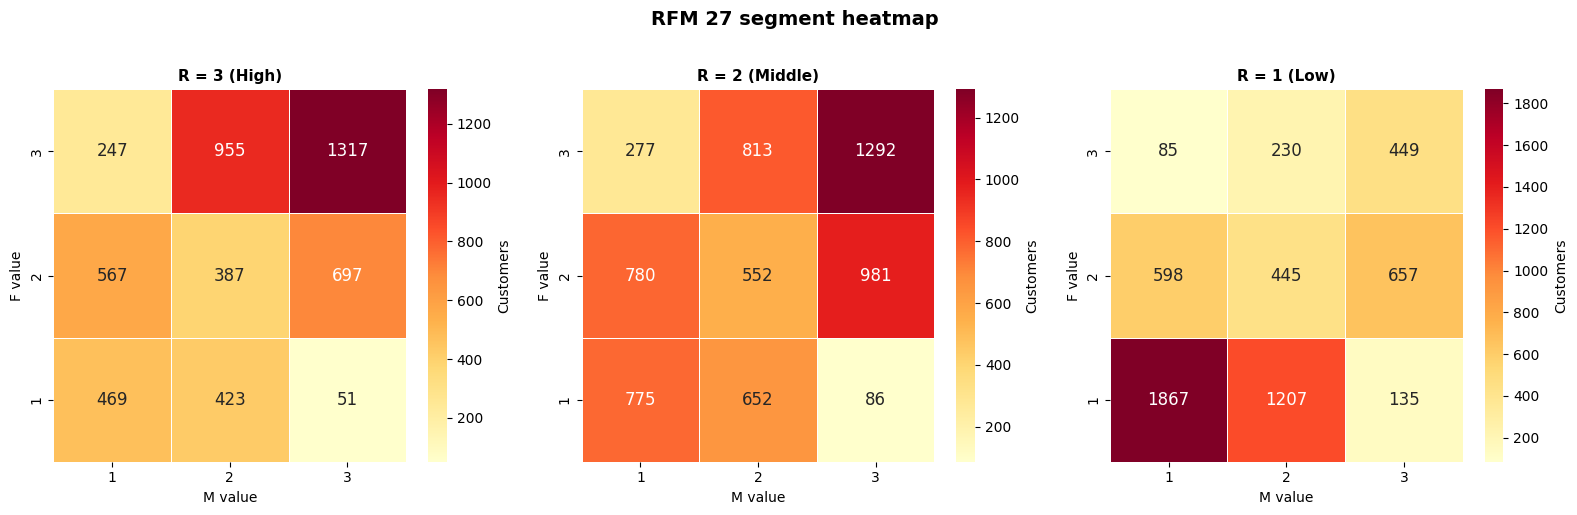


전체 27개 세그먼트 고객 수 (상위 10개):
RFM_segment  count
      1-1-1   1867
      3-3-3   1317
      2-3-3   1292
      1-1-2   1207
      2-2-3    981
      3-3-2    955
      2-3-2    813
      2-2-1    780
      2-1-1    775
      3-2-3    697


In [ ]:
# ── 27개 세그먼트 고객 수 히트맵 ─────────────────────────────────────────
seg_count = rfm.groupby('RFM_segment').size().reset_index(name='count')
seg_count[['R','F','M']] = seg_count['RFM_segment'].str.split('-', expand=True).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, r_val in enumerate([3, 2, 1]):
    sub = seg_count[seg_count['R'] == r_val].pivot(index='F', columns='M', values='count').fillna(0)
    sub = sub.reindex(index=[3,2,1], columns=[1,2,3])
    sns.heatmap(sub, annot=True, fmt='.0f', cmap='YlOrRd',
                linewidths=0.5, ax=axes[idx],
                cbar_kws={'label': 'Customers'},
                annot_kws={'size': 12})
    axes[idx].set_title(f'R = {r_val} ({"High" if r_val==3 else "Middle" if r_val==2 else "Low"})',
                        fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('M value')
    axes[idx].set_ylabel('F value')

plt.suptitle('RFM 27 segment heatmap', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n전체 27개 세그먼트 고객 수 (상위 10개):')
print(seg_count.sort_values('count', ascending=False)[['RFM_segment','count']].head(10).to_string(index=False))

### 4-3. RFM 합산 점수 기반 고객 등급 분류

합산 점수(3~9점)를 3구간으로 나눠 **VIP / 일반 / 이탈위험** 등급을 부여한다.

| 등급 | RFM 합산 점수 | 의미 |
|---|---|---|
| **VIP** | 7~9점 | 최근·자주·많이 구매하는 최우수 고객 |
| **일반** | 5~6점 | 평균 수준의 거래 패턴 |
| **이탈위험** | 3~4점 | 구매 빈도·금액·최근성 모두 낮음 |

In [ ]:
def rfm_grade(total):
    if total >= 7: return 'VIP'
    elif total >= 5: return '일반'
    else: return '이탈위험'

rfm['RFM_grade'] = rfm['RFM_total'].apply(rfm_grade)

grade_count = rfm['RFM_grade'].value_counts()
print('RFM 등급별 고객 수:')
for grade, cnt in grade_count.items():
    pct = cnt / len(rfm) * 100
    print(f'  {grade:6s}: {cnt:6,}명 ({pct:.1f}%)')

# 등급별 RFM 평균
print('\n등급별 R / F / M 평균:')
print(rfm.groupby('RFM_grade')[['R_score','F_score','M_score',
                                 'last_hour','tr_cnt','tr_amt']]
      .mean().round(2))

RFM 등급별 고객 수:
  VIP   :  7,189명 (42.3%)
  일반    :  5,358명 (31.5%)
  이탈위험  :  4,447명 (26.2%)

등급별 R / F / M 평균:
           R_score  F_score  M_score  last_hour  tr_cnt  tr_amt
RFM_grade                                                      
VIP           2.45     2.70     2.63     671.66   12.26  175.59
이탈위험          1.17     1.13     1.27     489.35    3.43   27.34
일반            1.98     1.78     1.76     636.84    6.63   73.04


/tmp/ipykernel_2536/3711079692.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2536/3711079692.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2536/3711079692.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


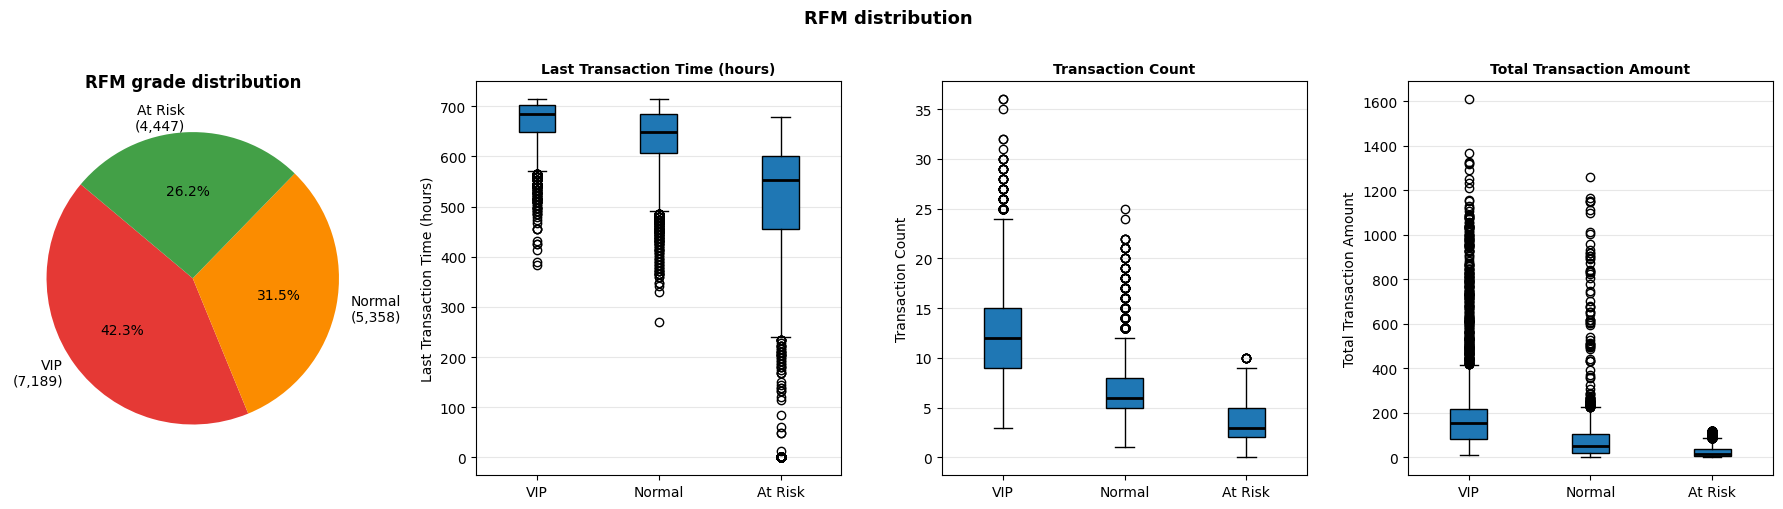

In [ ]:
# ── RFM 등급 파이차트 + 박스플롯 ─────────────────────────────────────────
grade_colors = {'VIP': '#E53935', '일반': '#FB8C00', '이탈위험': '#43A047'}
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# 파이차트
grades = grade_count.index.tolist()
axes[0].pie(
    grade_count.values,
    labels=[f"{grade_map[g]}\n({v:,})" for g, v in zip(grades, grade_count.values)],
    colors=[grade_colors[g] for g in grades],
    autopct='%1.1f%%',
    startangle=140,
    textprops={'fontsize': 10}
)
axes[0].set_title('RFM grade distribution', fontsize=12, fontweight='bold')

# R/F/M 박스플롯
for ax, metric, ylabel in zip(
    axes[1:],
    ['last_hour', 'tr_cnt', 'tr_amt'],
    ['Last Transaction Time (hours)', 'Transaction Count', 'Total Transaction Amount']
):
    data_by_grade = [
        rfm[rfm['RFM_grade'] == g][metric].dropna()
        for g in ['VIP', '일반', '이탈위험']
    ]

    bp = ax.boxplot(
        data_by_grade,
        patch_artist=True,
        medianprops={'color': 'black', 'linewidth': 2}
    )
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([grade_map[g] for g in ['VIP', '일반', '이탈위험']])

    ax.set_ylabel(ylabel)
    ax.set_title(ylabel, fontsize=10, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('RFM distribution', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 5단계: 고객 군집별 성별·연령대 특징 분석

### 5-1. 성별 × RFM 등급 분포

In [ ]:
# ── 성별 × RFM 등급 교차표 ───────────────────────────────────────────────
gender_grade = pd.crosstab(rfm['gender'], rfm['RFM_grade'], margins=True)
print('성별 × RFM 등급 교차표:')
print(gender_grade)

# 비율 계산
gender_grade_pct = pd.crosstab(rfm['gender'], rfm['RFM_grade'], normalize='index') * 100
print('\n성별 내 RFM 등급 비율 (%):')
print(gender_grade_pct.round(1))

성별 × RFM 등급 교차표:
RFM_grade   VIP  이탈위험    일반    All
gender                            
F          3035  1243  1847   6125
M          3728  2189  2566   8483
O            97    54    61    212
All        6860  3486  4474  14820

성별 내 RFM 등급 비율 (%):
RFM_grade   VIP  이탈위험    일반
gender                     
F          49.6  20.3  30.2
M          43.9  25.8  30.2
O          45.8  25.5  28.8


In [ ]:
# 카이제곱 독립성 검정: 성별 × RFM 등급
stat, p, dof, _ = chi2_contingency(pd.crosstab(rfm['gender'], rfm['RFM_grade']))
print(f'카이제곱 통계량 : {stat:.4f}')
print(f'p-value         : {p:.4e}')
print(f'자유도          : {dof}')


카이제곱 통계량 : 70.5672
p-value         : 1.7228e-14
자유도          : 4


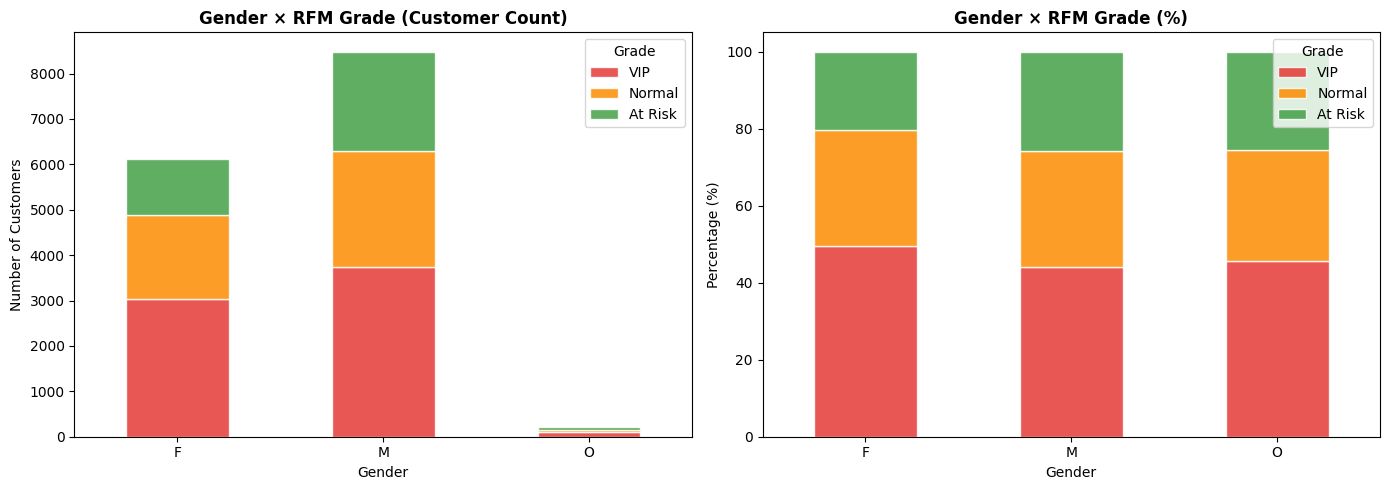

카이제곱 검정: χ²=70.5672, p=1.7228e-14, df=4
→ 유의수준 0.05에서 성별과 RFM 등급 간 유의한 연관성이 있다.


In [ ]:
# mapping
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}
gender_map = {'남': 'Male', '여': 'Female'}  # adjust if needed

# colors
grade_colors = {'VIP': '#E53935', '일반': '#FB8C00', '이탈위험': '#43A047'}

# crosstab
gender_grade_abs = pd.crosstab(rfm['gender'], rfm['RFM_grade'])
gender_grade_pct = gender_grade_abs.div(gender_grade_abs.sum(axis=1), axis=0) * 100

# rename labels
gender_grade_abs.rename(index=gender_map, columns=grade_map, inplace=True)
gender_grade_pct.rename(index=gender_map, columns=grade_map, inplace=True)

# plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gender_grade_abs[['VIP', 'Normal', 'At Risk']].plot(
    kind='bar',
    ax=axes[0],
    stacked=True,
    color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
    edgecolor='white',
    alpha=0.85
)
axes[0].set_title('Gender × RFM Grade (Customer Count)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Grade')

gender_grade_pct[['VIP', 'Normal', 'At Risk']].plot(
    kind='bar',
    ax=axes[1],
    stacked=True,
    color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
    edgecolor='white',
    alpha=0.85
)
axes[1].set_title('Gender × RFM Grade (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Percentage (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Grade')

plt.tight_layout()
plt.show()

ct = pd.crosstab(rfm['gender'], rfm['RFM_grade'])
stat, p, dof, _ = chi2_contingency(ct)

print(f'카이제곱 검정: χ²={stat:.4f}, p={p:.4e}, df={dof}')
print(f'→ {"유의수준 0.05에서 성별과 RFM 등급 간 유의한 연관성이 있다." if p < 0.05 else "유의한 연관성이 없다."}')

### 5-2. 연령대 × RFM 등급 분포

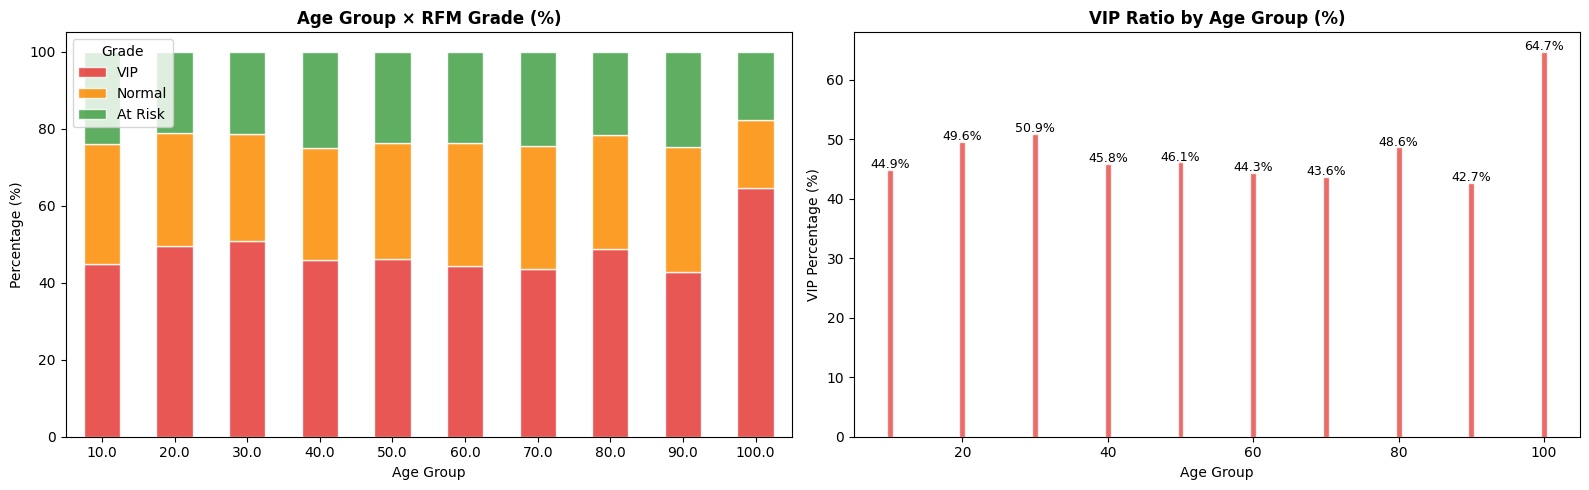

In [ ]:
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

age_grade = pd.crosstab(rfm['age_grp'], rfm['RFM_grade'], normalize='index') * 100
age_grade = age_grade.reindex(columns=['VIP','일반','이탈위험'])

age_grade.rename(columns=grade_map, inplace=True)

age_grade[['VIP', 'Normal', 'At Risk']].plot(
    kind='bar',
    ax=axes[0],
    stacked=True,
    color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
    edgecolor='white',
    alpha=0.85
)
axes[0].set_title('Age Group × RFM Grade (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Percentage (%)')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Grade')

vip_by_age = (
    rfm[rfm['RFM_grade']=='VIP']
    .groupby('age_grp')
    .size() / rfm.groupby('age_grp').size() * 100
)

axes[1].bar(
    vip_by_age.index,
    vip_by_age.values,
    color=grade_colors['VIP'],
    alpha=0.75,
    edgecolor='white'
)
axes[1].set_title('VIP Ratio by Age Group (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('VIP Percentage (%)')

for x, y in zip(vip_by_age.index, vip_by_age.values):
    axes[1].text(x, y + 0.3, f'{y:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 5-3. RFM 등급별 주요 지표 프로파일

In [ ]:
profile_cols = ['R_score','F_score','M_score','RFM_total',
                'last_hour','tr_cnt','tr_amt',
                'offer_received','response_ratio','income']

grade_profile = rfm.groupby('RFM_grade')[profile_cols].mean().round(3)
print('RFM 등급별 평균 프로파일:')
grade_profile

RFM 등급별 평균 프로파일:


,R_score,F_score,M_score,RFM_total,last_hour,tr_cnt,tr_amt,offer_received,response_ratio,income
RFM_grade,,,,,,,,,,
VIP,2.446,2.699,2.632,7.776,671.657,12.263,175.587,4.622,0.651,65321.429
이탈위험,1.174,1.134,1.271,3.580,489.354,3.429,27.340,4.362,0.176,65044.177
일반,1.983,1.781,1.757,5.521,636.839,6.630,73.035,4.414,0.376,65820.519


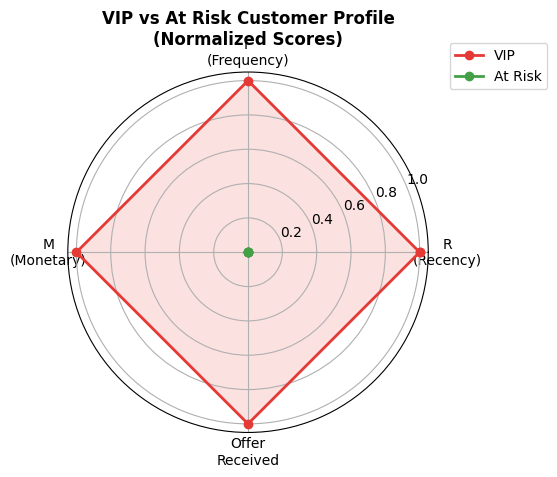

In [ ]:
# mapping
grade_map = {'VIP': 'VIP', '이탈위험': 'At Risk'}

radar_metrics = ['R_score','F_score','M_score','offer_received']
radar_labels  = ['R\n(Recency)', 'F\n(Frequency)', 'M\n(Monetary)', 'Offer\nReceived']

N = len(radar_metrics)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={'polar': True})

for grade, color in [('VIP','#E53935'), ('이탈위험','#43A047')]:
    vals = grade_profile.loc[grade, radar_metrics].tolist()

    max_v = grade_profile[radar_metrics].max()
    min_v = grade_profile[radar_metrics].min()

    vals_norm = [
        (v - min_v[m]) / (max_v[m] - min_v[m] + 1e-9)
        for v, m in zip(vals, radar_metrics)
    ]
    vals_norm += vals_norm[:1]

    ax.plot(
        angles,
        vals_norm,
        'o-',
        linewidth=2,
        color=color,
        label=grade_map[grade]  # 🔥 legend fix
    )
    ax.fill(angles, vals_norm, alpha=0.15, color=color)

ax.set_thetagrids(np.degrees(angles[:-1]), radar_labels)

ax.set_title(
    'VIP vs At Risk Customer Profile\n(Normalized Scores)',
    fontsize=12,
    fontweight='bold',
    pad=20
)

ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))

plt.tight_layout()
plt.show()

> **Note:** 이 레이더 차트는 두 등급(VIP, 이탈위험)만으로 min–max 정규화하기 때문에 이탈위험의 모든 값이 0으로 표시된다. 실제 수치 비교는 위의 등급별 평균 프로파일 표를 참고한다.


---
## 6단계: Demographic 세분화를 통한 오퍼 반응 분석

### 6-1. 성별 × 오퍼 반응률

In [ ]:
# 성별 오퍼 반응률 비교
gender_response = rfm[rfm['gender'].isin(['M','F'])].groupby('gender').agg(
    고객수         = ('id', 'count'),
    평균_반응률    = ('response_ratio', 'mean'),
    BOGO_반응률   = ('bogo_ratio', 'mean'),
    Discount_반응률= ('dc_ratio', 'mean'),
    평균_거래건수  = ('tr_cnt', 'mean'),
    평균_거래금액  = ('tr_amt', 'mean')
).round(4)

print('성별 오퍼 반응률 비교:')
gender_response

성별 오퍼 반응률 비교:


,고객수,평균_반응률,BOGO_반응률,Discount_반응률,평균_거래건수,평균_거래금액
gender,,,,,,
F,6125,0.5635,0.6789,0.7279,8.0598,140.9809
M,8483,0.4312,0.4913,0.5811,8.5808,99.5907


### 6-2. 연령대 × RFM 등급 × 오퍼 반응률 분석

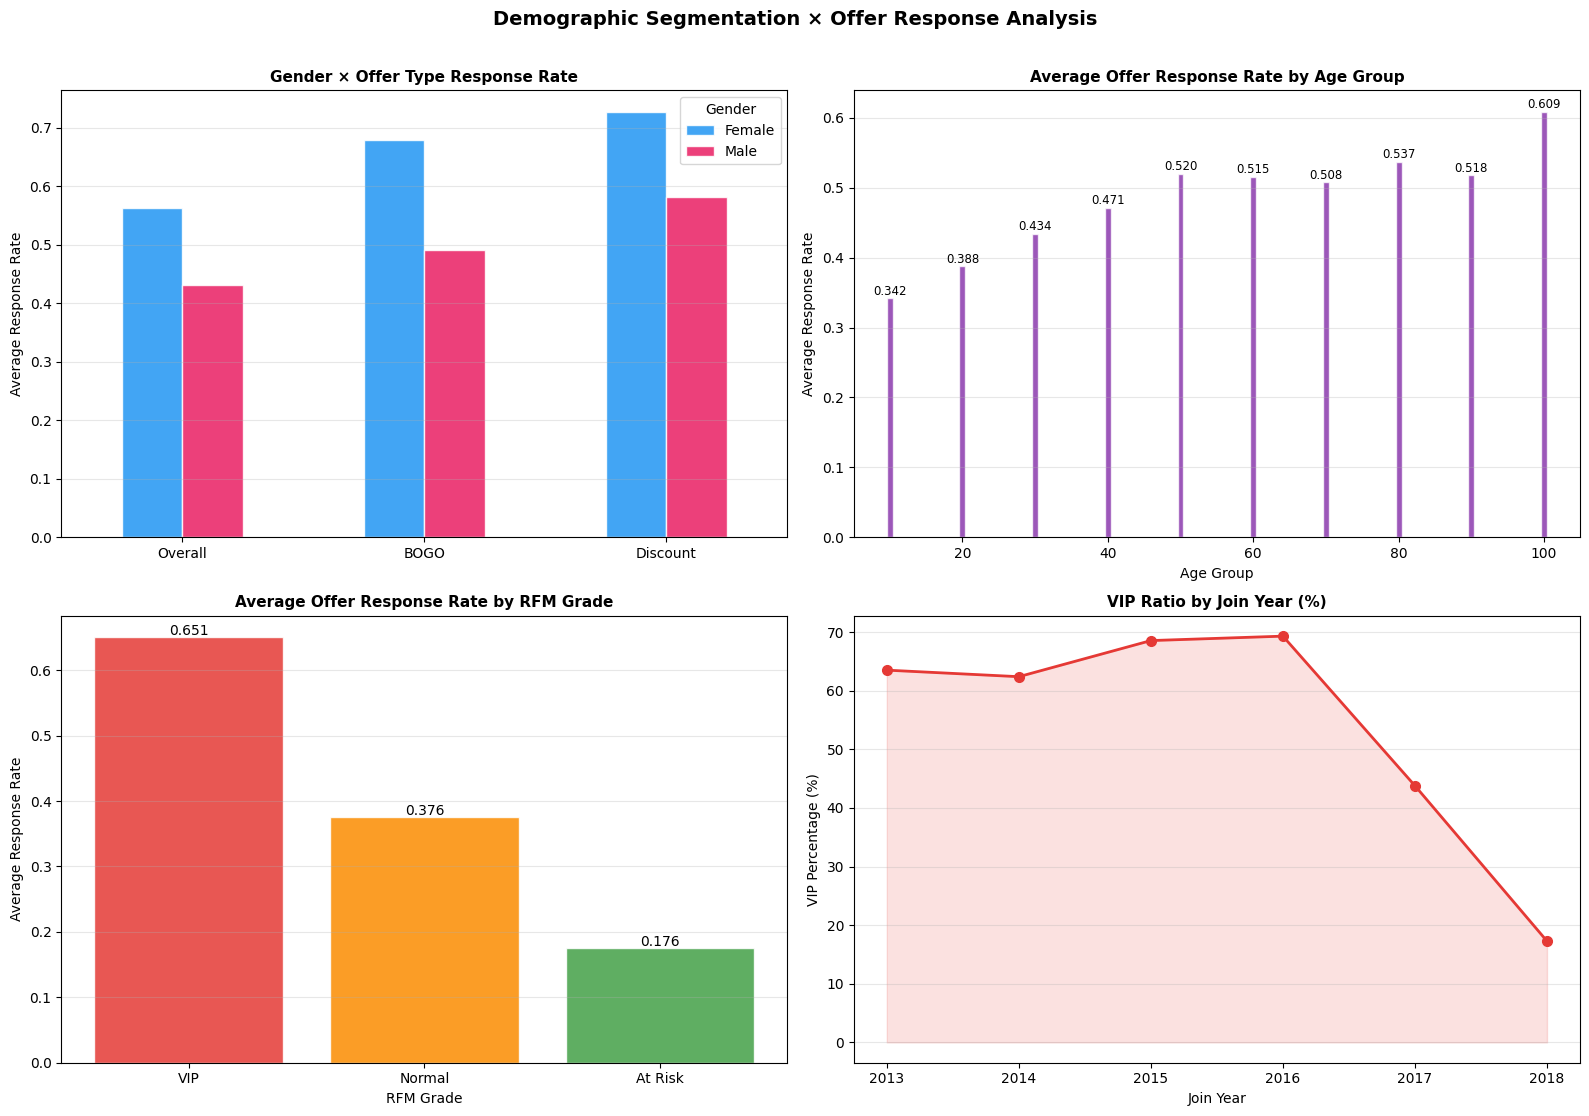

In [ ]:
# mappings
gender_map = {'M': 'Male', 'F': 'Female'}
age_map = {
    '10대': 'Teens', '20대': '20s', '30대': '30s',
    '40대': '40s', '50대': '50s', '60대 이상': '60+'
}
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# (1) Gender × Offer Type Response
df_g = rfm[rfm['gender'].isin(['M','F'])]
g_means = df_g.groupby('gender')[['response_ratio','bogo_ratio','dc_ratio']].mean()
g_means.rename(index=gender_map, inplace=True)

g_means.T.plot(
    kind='bar',
    ax=axes[0,0],
    color=['#2196F3','#E91E63'],
    edgecolor='white',
    alpha=0.85
)

axes[0,0].set_title('Gender × Offer Type Response Rate', fontsize=11, fontweight='bold')
axes[0,0].set_xticklabels(['Overall', 'BOGO', 'Discount'], rotation=0)
axes[0,0].set_ylabel('Average Response Rate')
axes[0,0].legend(title='Gender')
axes[0,0].grid(axis='y', alpha=0.3)

# (2) Age Group Response
age_resp = rfm.groupby('age_grp')['response_ratio'].mean()
age_resp.rename(index=age_map, inplace=True)

axes[0,1].bar(
    age_resp.index,
    age_resp.values,
    color='#7B1FA2',
    alpha=0.75,
    edgecolor='white'
)
axes[0,1].set_title('Average Offer Response Rate by Age Group', fontsize=11, fontweight='bold')
axes[0,1].set_xlabel('Age Group')
axes[0,1].set_ylabel('Average Response Rate')

for x, y in zip(age_resp.index, age_resp.values):
    axes[0,1].text(x, y+0.005, f'{y:.3f}', ha='center', fontsize=8.5)

axes[0,1].grid(axis='y', alpha=0.3)

# (3) RFM Grade Response
grade_resp = (
    rfm.groupby('RFM_grade')['response_ratio']
    .mean()
    .reindex(['VIP','일반','이탈위험'])
)
grade_resp.rename(index=grade_map, inplace=True)

bars = axes[1,0].bar(
    grade_resp.index,
    grade_resp.values,
    color=[grade_colors[g] for g in ['VIP','일반','이탈위험']],
    edgecolor='white',
    alpha=0.85
)

axes[1,0].set_title('Average Offer Response Rate by RFM Grade', fontsize=11, fontweight='bold')
axes[1,0].set_xlabel('RFM Grade')
axes[1,0].set_ylabel('Average Response Rate')

for bar in bars:
    axes[1,0].text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.003,
        f'{bar.get_height():.3f}',
        ha='center',
        fontsize=10
    )

axes[1,0].grid(axis='y', alpha=0.3)

# (4) VIP Ratio by Join Year
year_vip = (
    rfm[rfm['RFM_grade']=='VIP'].groupby('n_year').size()
    / rfm.groupby('n_year').size()
    * 100
).dropna()

axes[1,1].plot(
    year_vip.index,
    year_vip.values,
    marker='o',
    color='#E53935',
    linewidth=2,
    markersize=7
)
axes[1,1].fill_between(year_vip.index, year_vip.values, alpha=0.15, color='#E53935')

axes[1,1].set_title('VIP Ratio by Join Year (%)', fontsize=11, fontweight='bold')
axes[1,1].set_xlabel('Join Year')
axes[1,1].set_ylabel('VIP Percentage (%)')
axes[1,1].grid(axis='y', alpha=0.3)

plt.suptitle('Demographic Segmentation × Offer Response Analysis',
             fontsize=14, fontweight='bold', y=1.01)

plt.tight_layout()
plt.show()

### 6-3. 성별 × 연령대 × RFM 등급 — 종합 교차 분석

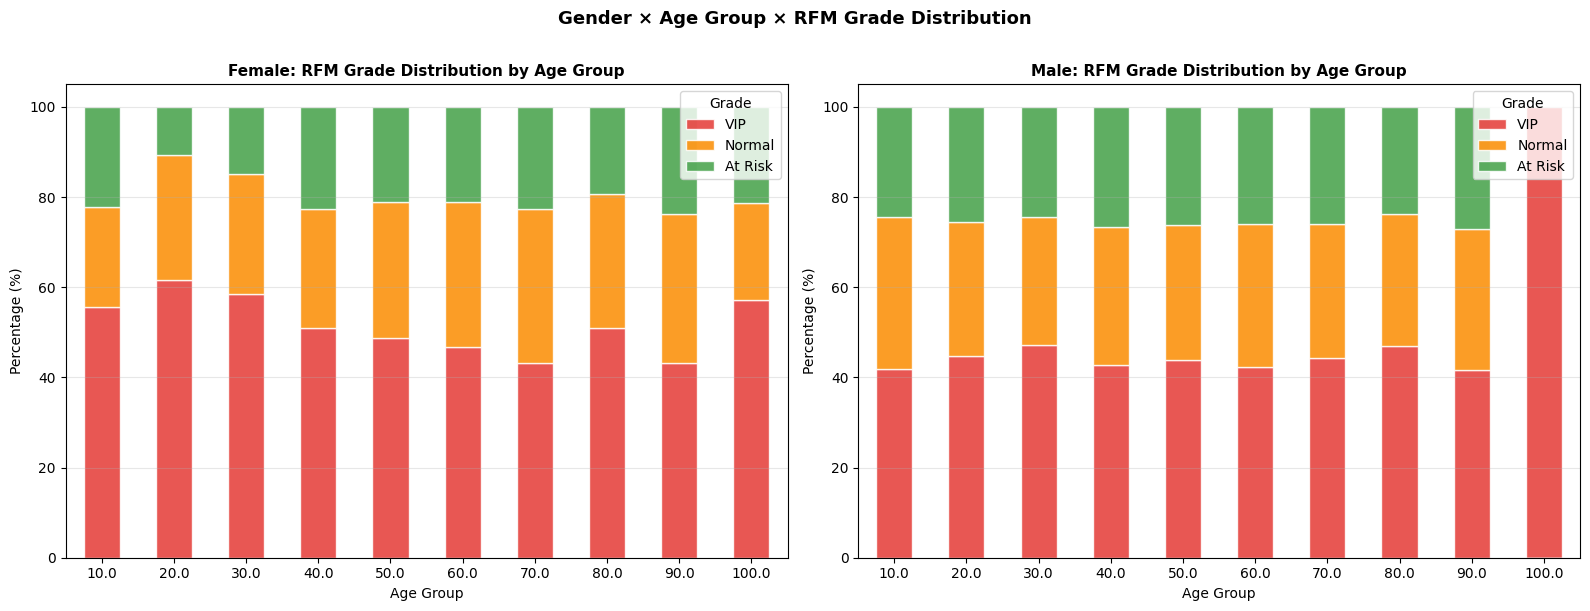

In [ ]:
gender_map = {'F': 'Female', 'M': 'Male'}
age_map = {
    '10대': 'Teens', '20대': '20s', '30대': '30s',
    '40대': '40s', '50대': '50s', '60대 이상': '60+'
}
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}

cross = rfm[rfm['gender'].isin(['M','F'])]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, gender, color in zip(axes, ['F','M'], ['#E91E63','#2196F3']):
    sub = cross[cross['gender'] == gender]

    pivot_data = (
        sub.groupby(['age_grp','RFM_grade'])
        .size()
        .unstack(fill_value=0)
    )

    pivot_data = pivot_data.reindex(columns=['VIP','일반','이탈위험'], fill_value=0)

    pivot_data.rename(index=age_map, columns=grade_map, inplace=True)

    pivot_pct = pivot_data.div(pivot_data.sum(axis=1), axis=0) * 100

    pivot_pct[['VIP','Normal','At Risk']].plot(
        kind='bar',
        ax=ax,
        stacked=True,
        color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
        edgecolor='white',
        alpha=0.85
    )

    ax.set_title(
        f'{gender_map[gender]}: RFM Grade Distribution by Age Group',
        fontsize=11,
        fontweight='bold'
    )
    ax.set_xlabel('Age Group')
    ax.set_ylabel('Percentage (%)')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Grade', loc='upper right')
    ax.grid(axis='y', alpha=0.3)

plt.suptitle(
    'Gender × Age Group × RFM Grade Distribution',
    fontsize=13,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.show()

### 6-4. 오퍼 유형별 반응률 — RFM 등급 × 성별 × 연령대

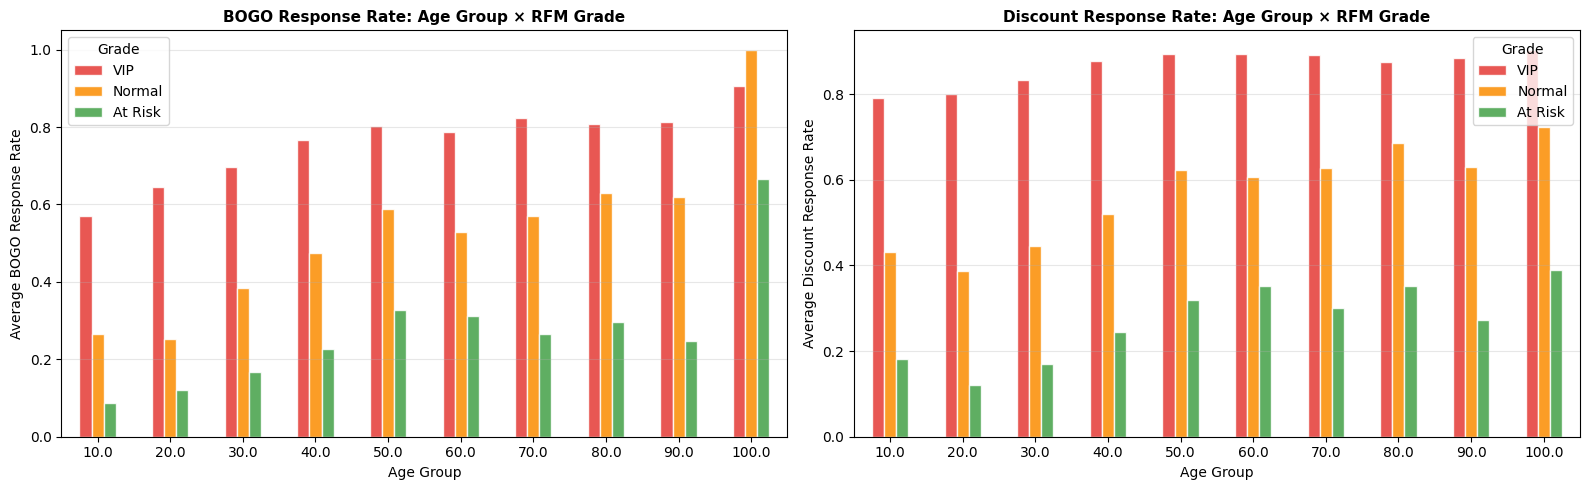

In [ ]:
age_map = {
    '10대': 'Teens', '20대': '20s', '30대': '30s',
    '40대': '40s', '50대': '50s', '60대 이상': '60+'
}
grade_map = {'VIP': 'VIP', '일반': 'Normal', '이탈위험': 'At Risk'}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- BOGO ---
bogo_pivot = (
    rfm.groupby(['age_grp','RFM_grade'])['bogo_ratio']
    .mean()
    .unstack()
)

bogo_pivot = bogo_pivot.reindex(columns=['VIP','일반','이탈위험'])

bogo_pivot.rename(index=age_map, columns=grade_map, inplace=True)

bogo_pivot[['VIP','Normal','At Risk']].plot(
    kind='bar',
    ax=axes[0],
    color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
    edgecolor='white',
    alpha=0.85
)

axes[0].set_title('BOGO Response Rate: Age Group × RFM Grade', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Average BOGO Response Rate')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Grade')
axes[0].grid(axis='y', alpha=0.3)

# --- Discount ---
dc_pivot = (
    rfm.groupby(['age_grp','RFM_grade'])['dc_ratio']
    .mean()
    .unstack()
)

dc_pivot = dc_pivot.reindex(columns=['VIP','일반','이탈위험'])

dc_pivot.rename(index=age_map, columns=grade_map, inplace=True)

dc_pivot[['VIP','Normal','At Risk']].plot(
    kind='bar',
    ax=axes[1],
    color=[grade_colors['VIP'], grade_colors['일반'], grade_colors['이탈위험']],
    edgecolor='white',
    alpha=0.85
)

axes[1].set_title('Discount Response Rate: Age Group × RFM Grade', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Average Discount Response Rate')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Grade')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7단계: 최종 RFM 마트 테이블 확인

In [ ]:
print('최종 RFM 마트 테이블 컬럼 정의:')
rfm_col_desc = {
    'id'            : '고객 고유 식별자',
    'gender'        : '성별 (M/F)',
    'age'           : '나이',
    'age_grp'       : '연령대 (10년 단위)',
    'income'        : '연간 소득',
    'n_year'        : '회원 가입 연도',
    'last_hour'     : 'R — 마지막 거래 시각 (hours_since_start)',
    'tr_cnt'        : 'F — 거래 건수',
    'tr_amt'        : 'M — 총 거래 금액',
    'R_score'       : 'R 점수 (1~3, 클수록 최근)',
    'F_score'       : 'F 점수 (1~3, 클수록 자주)',
    'M_score'       : 'M 점수 (1~3, 클수록 많이)',
    'RFM_segment'   : 'RFM 세그먼트 코드 (예: 3-2-1)',
    'RFM_total'     : 'RFM 합산 점수 (3~9)',
    'RFM_grade'     : 'RFM 등급 (VIP / 일반 / 이탈위험)',
    'offer_received': '수신한 오퍼 총 건수',
    'response_cnt'  : '완료한 오퍼 건수',
    'response_ratio': '전체 오퍼 반응률',
    'bogo_ratio'    : 'BOGO 오퍼 반응률',
    'dc_ratio'      : 'Discount 오퍼 반응률',
}
for col, desc in rfm_col_desc.items():
    print(f'  {col:<18} : {desc}')

print(f'\n총 고객 수: {len(rfm):,}명  |  컬럼 수: {rfm.shape[1]}개')
rfm.head(5)

최종 RFM 마트 테이블 컬럼 정의:
  id                 : 고객 고유 식별자
  gender             : 성별 (M/F)
  age                : 나이
  age_grp            : 연령대 (10년 단위)
  income             : 연간 소득
  n_year             : 회원 가입 연도
  last_hour          : R — 마지막 거래 시각 (hours_since_start)
  tr_cnt             : F — 거래 건수
  tr_amt             : M — 총 거래 금액
  R_score            : R 점수 (1~3, 클수록 최근)
  F_score            : F 점수 (1~3, 클수록 자주)
  M_score            : M 점수 (1~3, 클수록 많이)
  RFM_segment        : RFM 세그먼트 코드 (예: 3-2-1)
  RFM_total          : RFM 합산 점수 (3~9)
  RFM_grade          : RFM 등급 (VIP / 일반 / 이탈위험)
  offer_received     : 수신한 오퍼 총 건수
  response_cnt       : 완료한 오퍼 건수
  response_ratio     : 전체 오퍼 반응률
  bogo_ratio         : BOGO 오퍼 반응률
  dc_ratio           : Discount 오퍼 반응률

총 고객 수: 16,994명  |  컬럼 수: 24개


,id,gender,age,age_grp,income,n_year,last_hour,tr_cnt,tr_amt,offer_received,...,bogo_response,dc_response,bogo_ratio,dc_ratio,R_score,F_score,M_score,RFM_segment,RFM_total,RFM_grade
0,0009655768c64bdeb2e877511632db8f,M,33.0,30.0,72000.0,2017.0,696.0,8,127.60,5,...,1,2,1.0,1.0,3,2,3,3-2-3,8,VIP
1,00116118485d4dfda04fdbaba9a87b5c,NaN,NaN,NaN,NaN,NaN,474.0,3,4.09,2,...,0,0,0.0,NaN,1,1,1,1-1-1,3,이탈위험
2,0011e0d4e6b944f998e987f904e8c1e5,O,40.0,40.0,57000.0,2018.0,654.0,5,79.46,5,...,1,2,1.0,1.0,2,1,2,2-1-2,5,일반
3,0020c2b971eb4e9188eac86d93036a77,F,59.0,50.0,90000.0,2016.0,708.0,8,196.86,5,...,1,2,0.5,1.0,3,2,3,3-2-3,8,VIP
4,0020ccbbb6d84e358d3414a3ff76cffd,F,24.0,20.0,60000.0,2016.0,672.0,12,154.05,4,...,2,1,1.0,1.0,2,3,3,2-3-3,8,VIP


In [ ]:
rfm[['R_score','F_score','M_score','RFM_total',
     'last_hour','tr_cnt','tr_amt',
     'response_ratio','bogo_ratio','dc_ratio']].describe().round(4)

,R_score,F_score,M_score,RFM_total,last_hour,tr_cnt,tr_amt,response_ratio,bogo_ratio,dc_ratio
count,16994.000,16994.0000,16994.0000,16994.000,16994.0000,16994.0000,16994.0000,16994.0000,14992.0000,14945.0000
mean,1.967,2.0000,2.0000,5.967,612.9741,8.1754,104.4605,0.4400,0.5125,0.5852
std,0.796,0.8165,0.8165,1.819,127.4773,5.1163,125.9379,0.3394,0.4479,0.4401
min,1.000,1.0000,1.0000,3.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,1.000,1.0000,1.0000,4.000,588.0000,4.0000,21.8200,0.1667,0.0000,0.0000
50%,2.000,2.0000,2.0000,6.000,648.0000,7.0000,69.4150,0.5000,0.5000,0.6667
75%,3.000,3.0000,3.0000,8.000,690.0000,11.0000,148.8275,0.7500,1.0000,1.0000
max,3.000,3.0000,3.0000,9.000,714.0000,36.0000,1608.6900,1.0000,1.0000,1.0000


---
## 8단계: 세그먼트별 마케팅 전략 수립

분석 결과를 바탕으로 각 RFM 등급 및 Demographic 세그먼트에 대한 맞춤 전략을 제안한다.

| 등급 | 주요 특성 | 추천 오퍼 전략 | 커뮤니케이션 컨셉 |
|---|---|---|---|
| **VIP** | 최근·자주·많이 구매, 높은 오퍼 반응률 | BOGO + Discount 복합 오퍼, 독점 멤버십 혜택 | "스타벅스 VIP 고객님께 특별한 혜택을 드립니다" |
| **일반** | 평균적 거래 패턴 | Discount 오퍼 우선 (반응률 0.64로 가장 높음) | "더 자주 방문할수록 더 많은 혜택" |
| **이탈위험** | 오래전 방문, 낮은 빈도·금액 | 저난이도 소액 Discount, Informational 오퍼로 재유입 | "스타벅스가 그립지 않으신가요?" |

### Demographic 기반 세부 전략

| 세그먼트 | 인사이트 | 전략 |
|---|---|---|
| 60~70대 고연령 | VIP 비율 가장 높음 | BOGO 오퍼 + 충성도 프로그램 강화 |
| 20~30대 저연령 | VIP 비율 낮음, 이탈위험 높음 | 모바일 채널 중심 소액 Discount 오퍼로 습관 형성 |
| 여성(F) | BOGO 반응률 상대적으로 높음 | BOGO 오퍼 우선 배분 |
| 남성(M) | Discount 선호 경향 | Discount 오퍼 위주 타깃팅 |
| 2013~2015년 가입 (장기회원) | 반응률 안정적으로 높음 | VIP 유지 프로그램, 장기 충성도 보상 |

---
## 요약 및 결론

### 1) RFM 세분화 결과
- 스타벅스 캠페인 데이터를 활용하여 고객 단위의 R(최근 거래 시각), F(거래 건수), M(총 거래 금액)을 계산하고 각각 3분위 분할로 1~3점을 부여하였다.
- 3×3×3 = **27개 세그먼트**가 생성되었으며, RFM 합산 점수(3~9점)를 기준으로 **VIP / 일반 / 이탈위험** 3단계 등급으로 재분류하였다.

### 2) 군집별 성별·연령대 특징
- **VIP 고객군**(42.3%)은 평균 거래 12.3건, 총 거래금액 175.6, 오퍼 반응률 0.651로 이탈위험군(3.4건, 27.3, 0.176)과 뚜렷이 구분된다. 반면 평균 소득은 세 등급 모두 약 65,000 수준으로 거의 같아, RFM 등급 차이는 소득이 아니라 이용 행동에서 비롯된다.
- **연령대별 등급 구성**은 비교적 균일하다(10–90대의 VIP 비율 약 43–51%). 고객 수가 매우 적은 100세 이상 구간을 제외하면 특정 연령대가 이탈위험군에 집중되지 않는다.
- **성별**: 여성은 VIP 비율 49.6%, 이탈위험 20.3%로 남성(43.9%, 25.8%)보다 우량 고객 비중이 높으며, 성별과 RFM 등급 간의 연관성은 카이제곱 검정으로 유의하다(χ² = 70.6, p < 0.001).

### 3) Demographic 세분화 × 오퍼 반응
- **Discount 오퍼**의 평균 반응률(0.644)이 BOGO(0.572)보다 높으며, 모든 등급·연령대에서 공통적으로 유효한 오퍼 유형이다.
- **VIP 고객**은 이탈위험 고객 대비 오퍼 반응률이 현저히 높아, 오퍼 자원을 VIP에 집중하는 전략이 ROI를 극대화할 수 있다.
- **여성 고객**의 평균 오퍼 반응률(0.564)이 남성(0.431)보다 높고, BOGO(0.679 vs 0.491)와 Discount(0.728 vs 0.581) 모두에서 같은 경향을 보인다.
- 이탈위험 고객에게는 저난이도 Discount 오퍼와 Informational 오퍼를 통한 단계적 재유입 전략이 적합하다.